# NASDAQ-100 opening-range breakouts: forward-return walkthrough

This notebook reproduces the headline results from the saved per-breakout ledger
(`results/breakout_ledger.csv`). It needs no broker data. The ledger has one row per
New York opening-range breakout, 2022-01 → 2026-07, with forward returns already
normalised and net of the spread at the fill:

$$y_{i,h} \;=\; \frac{s_i\,(C_{t_i+h} - E_i)}{\mathrm{ATR}_{i}} \;-\; \frac{\mathrm{spread}_{t_i}}{\mathrm{ATR}_{i}}$$

where $s_i\in\{-1,+1\}$ is the breakout side, $E_i$ the stop-entry price, and $\mathrm{ATR}_i$ the
prior-day average true range. Positive means price kept going the way the breakout was taken.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "figures"))
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 140)

In [2]:
df = pd.read_csv(ROOT / "results" / "breakout_ledger.csv", parse_dates=["date"])
print(f"{len(df):,} breakouts, {df.date.min():%Y-%m-%d} -> {df.date.max():%Y-%m-%d}")
df.head()

1,082 breakouts, 2022-01-04 -> 2026-07-01


,date,dow,side,drift5_aligned,fwd_15,fwd_30,fwd_60,fwd_120,fwd_flat
0,2022-01-04,2,-1,1,0.2473,0.2814,0.8820,0.8898,0.5488
1,2022-01-05,3,1,0,-0.1834,-0.2667,-0.2262,-0.2726,-1.3245
2,2022-01-06,4,-1,1,-0.0400,-0.4465,-0.4859,-0.4597,-0.4213
3,2022-01-07,5,-1,0,0.1913,0.4428,0.2988,0.1884,0.1916
4,2022-01-10,1,-1,0,0.1473,0.1149,0.1117,-0.0368,-0.7423


## 1. Weekday table

For each weekday $d$: the mean $\bar y_d$, the t-statistic $t = \bar y_d / (s_d/\sqrt{n_d})$,
and a 95% bootstrap interval from 10,000 resamples.

In [3]:
rng = np.random.default_rng(20260813)
names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri"}
rows = []
for d in range(1, 6):
    v = df.loc[df.dow == d, "fwd_flat"].to_numpy()
    boot = rng.choice(v, (10_000, len(v))).mean(1)
    rows.append(dict(day=names[d], n=len(v), mean=v.mean(),
                     t=v.mean() / (v.std(ddof=1) / np.sqrt(len(v))),
                     ci_lo=np.percentile(boot, 2.5), ci_hi=np.percentile(boot, 97.5)))
pd.DataFrame(rows).set_index("day")

,n,mean,t,ci_lo,ci_hi
day,,,,,
Mon,201,-0.0144,-0.5658,-0.0633,0.0351
Tue,225,0.0717,2.6330,0.0176,0.1250
Wed,219,-0.0060,-0.1821,-0.0707,0.0584
Thu,220,0.0336,0.9298,-0.0361,0.1065
Fri,217,0.1409,4.5800,0.0810,0.2020


## 2. The selection-aware permutation test

Friday was picked because it won a five-way comparison, so a test that treats Friday as
chosen in advance overstates significance. The right null redoes the search inside each
permutation:

$$T^{\text{obs}} = \max_{d}\big(\bar y_{d} - \bar y_{\neg d}\big), \qquad
p = \frac{1}{B}\sum_{b=1}^{B} \mathbf 1\!\left[\max_{d}\big(\bar y^{(b)}_{d} - \bar y^{(b)}_{\neg d}\big) \ge T^{\text{obs}}\right]$$

where $(b)$ denotes the weekday labels shuffled across sessions, $B = 100{,}000$.

In [4]:
y, dow = df.fwd_flat.to_numpy(), df.dow.to_numpy()
best = lambda yy, dd: max(yy[dd == d].mean() - yy[dd != d].mean() for d in range(1, 6))
T_obs = best(y, dow)

# vectorised: B permutations in blocks, day means via masked sums
B, n, tot = 100_000, len(y), y.sum()
cnt = np.array([(dow == d).sum() for d in range(1, 6)])
rng = np.random.default_rng(7)
null = np.empty(B)
for i in range(0, B, 5_000):
    perm = rng.permuted(np.tile(dow, (5_000, 1)), axis=1)
    s = np.stack([(y * (perm == d)).sum(1) for d in range(1, 6)], 1)
    null[i:i + 5_000] = (s / cnt - (tot - s) / (n - cnt)).max(1)
print(f"observed best-day gap  {T_obs:+.4f} ATR (Friday)")
print(f"null mean {null.mean():+.4f}, 95th pct {np.percentile(null, 95):+.4f}")
p = (null >= T_obs).mean()
print(f"selection-aware p = {p:.4f}  (Monte-Carlo s.e. {np.sqrt(p * (1 - p) / B):.4f}, B = {B:,})")

observed best-day gap  +0.1185 ATR (Friday)
null mean +0.0452, 95th pct +0.0812
selection-aware p = 0.0017  (Monte-Carlo s.e. 0.0001, B = 100,000)


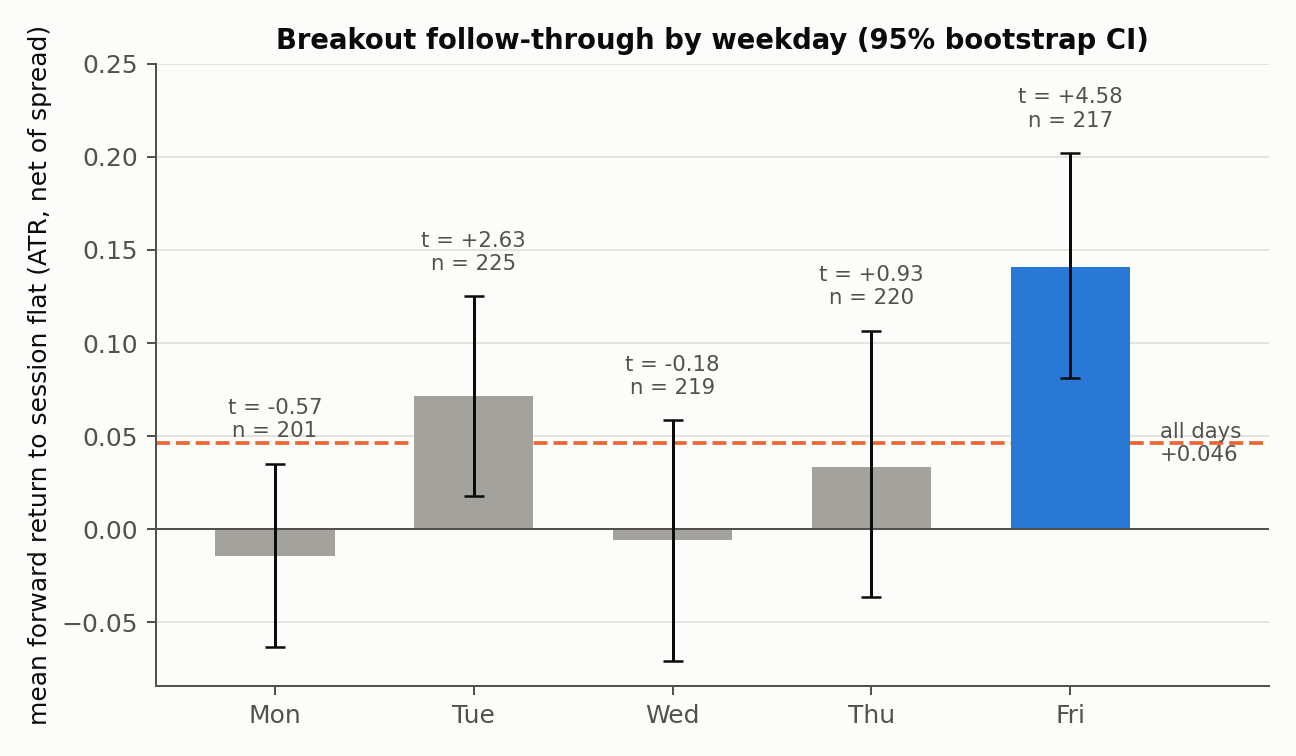

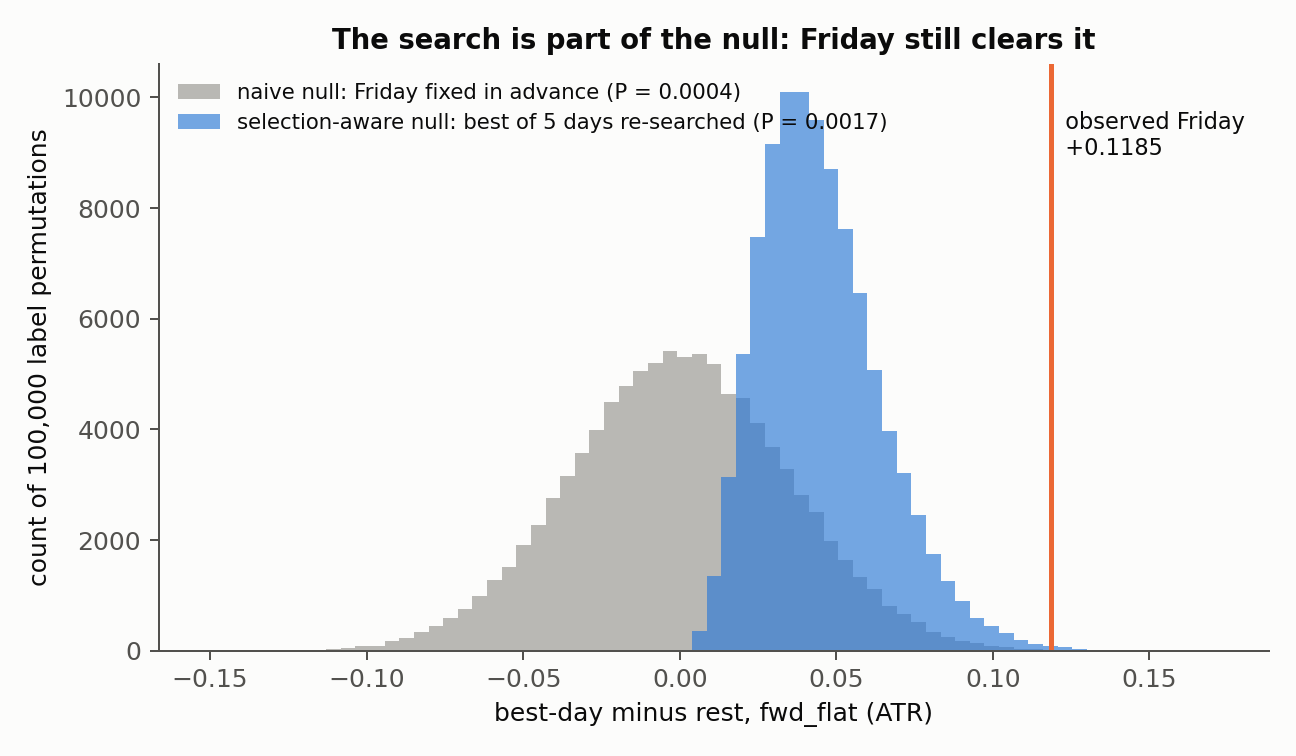

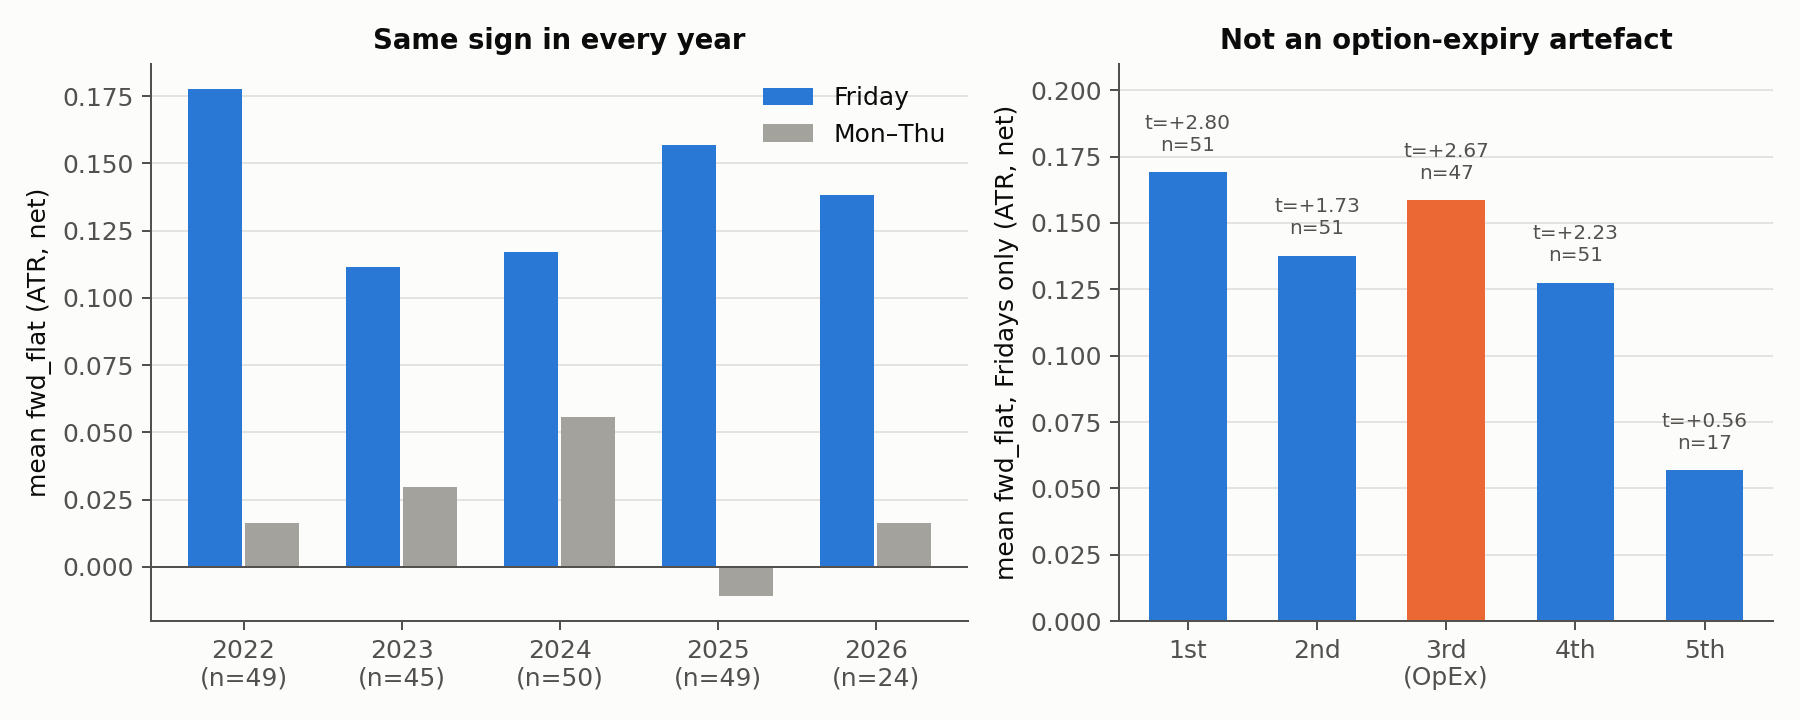

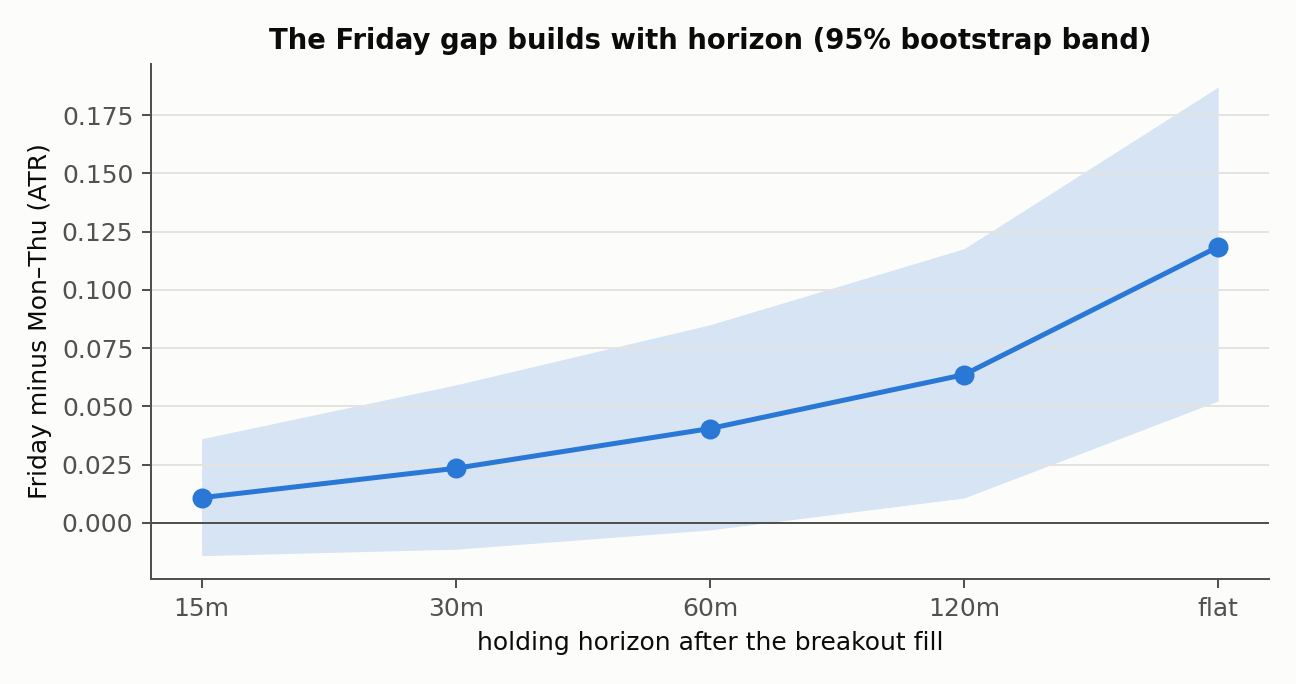

In [5]:
import make_figures as mf
mf.fig_weekday(df); mf.fig_null(df); mf.fig_stability(df); mf.fig_horizons(df)
for f in ["fig1_weekday_effect", "fig2_selection_aware_null", "fig3_stability", "fig4_horizon_profile"]:
    display(Image(filename=str(ROOT / "figures" / f"{f}.png"), width=760))

## 3. Robustness checks

Each year on its own, and Fridays split by week of the month (the 3rd Friday is the
monthly options expiry):

In [6]:
fri = df[df.dow == 5].assign(year=lambda x: x.date.dt.year, nth=lambda x: (x.date.dt.day - 1) // 7 + 1)
display(fri.groupby("year").fwd_flat.agg(["count", "mean"]))
fri.groupby("nth").fwd_flat.agg(["count", "mean"]).rename_axis("Friday of month")

,count,mean
year,,
2022,49,0.1776
2023,45,0.1115
2024,50,0.1169
2025,49,0.1569
2026,24,0.1381


,count,mean
Friday of month,,
1,51,0.1692
2,51,0.1376
3,47,0.1586
4,51,0.1275
5,17,0.0568


## 4. What this does and does not show

* The effect is a **forward-return** statistic. It is not a backtest with stops or position sizing.
* The fixed-horizon (60-minute) version of the best *single* day has selection-aware $p = 0.074$
  (`results/p4.log`). The result is strongest at the session-close horizon, and choosing that
  horizon is itself a modelling choice.
* 2026 has only half a year of data (n = 24 Fridays).
